# Project 1: Wealth Inequality in Denmark
Starter notebook. Add your names, code and interpretations. Keep your simulation module (.py) beside this notebook.

**Group name:** Anne-Sofie, Ida & Mathilde

**Members:** Ida S. Ahm, Mathilde M. Thorup & Anne-Sofie T. Hansen

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

## Download function
`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [1]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


## 1.1   Download and Read the Tables
Tasks and hints: PDF Section 1.1.

In [2]:
# FORMUE15 contains counts by wealth bracket, age, definition, price unit and year.
counts = download(
    'FORMUE15',
    FORMUE='*',
    DEFINITION='D20',  # 2020 wealth definition
    **settings,
)

# 1802 denotes all adults; the remaining codes are the eight age groups.
all_adults = '1802'
age_codes = ['1829', '3039', '4049', '5059', '6069', '7079', '8089', '9099']
age_labels = ['18–29', '30–39', '40–49', '50–59', '60–69', '70–79', '80–89', '90+']

percentiles_all = percentiles.loc[percentiles['ALDER'] == all_adults].copy()
percentiles_age = percentiles.loc[percentiles['ALDER'].isin(age_codes)].copy()
counts_all = counts.loc[counts['ALDER'] == all_adults].copy()
counts_age = counts.loc[counts['ALDER'].isin(age_codes)].copy()

print('FORMUE16:')
display(percentiles.head())
print('FORMUE15:')
display(counts.head())
print('All-adult age code:', all_adults)
print('Age groups in FORMUE16:', percentiles_age['ALDER'].nunique())
print('Age groups in FORMUE15:', counts_age['ALDER'].nunique())

FORMUE16:


,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


FORMUE15:


,FORMUE,DEFINITION,PRISENHED,ALDER,TID,value
0,0000M10,D20,006,1802,2024,39466
1,0000M10,D20,006,1829,2024,2345
2,0000M10,D20,006,3039,2024,11605
3,0000M10,D20,006,4049,2024,9680
4,0000M10,D20,006,5059,2024,8096


All-adult age code: 1802
Age groups in FORMUE16: 8
Age groups in FORMUE15: 8


## 1.2   Plot the Age Profiles
Tasks and hints: PDF Section 1.2.

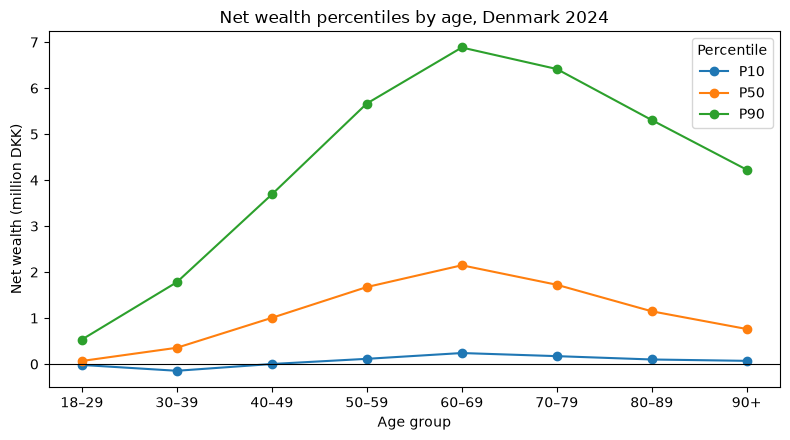

Age profile and percentile gaps (DKK):


percentile,10,50,90,upper_gap,lower_gap
18–29,-19750.0,66507.0,532429.0,465922.0,86257.0
30–39,-146586.0,353896.0,1780078.0,1426182.0,500482.0
40–49,912.0,1004750.0,3688269.0,2683519.0,1003838.0
50–59,113324.0,1674287.0,5665305.0,3991018.0,1560963.0
60–69,239280.0,2147564.0,6883537.0,4735973.0,1908284.0
70–79,171695.0,1724056.0,6415595.0,4691539.0,1552361.0
80–89,99096.0,1146853.0,5305568.0,4158715.0,1047757.0
90+,69252.0,761637.0,4225415.0,3463778.0,692385.0


Widest P90–P50 gap: 60–69, 4,735,973 DKK
Age groups with negative P10: ['18–29', '30–39']


In [3]:
# Turn percentile labels into numbers and reshape to one row per age group.
percentiles_age = percentiles_age.copy()
percentiles_age['percentile'] = percentiles_age['PERCENTIL'].str.replace('P', '', regex=False).astype(int)
wealth_percentiles = percentiles_age.pivot_table(
    index='ALDER', columns='percentile', values='value'
).reindex(index=age_codes, columns=range(1, 100))

# Plot P10, P50 and P90 in the published age-group order.
fig, ax = plt.subplots(figsize=(8, 4.5))
for percentile in [10, 50, 90]:
    ax.plot(age_labels, wealth_percentiles[percentile] / 1_000_000,
            marker='o', label=f'P{percentile}')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Age group')
ax.set_ylabel('Net wealth (million DKK)')
ax.set_title('Net wealth percentiles by age, Denmark 2024')
ax.legend(title='Percentile')
fig.tight_layout()
plt.show()

# Compare the upper and lower gaps within each age group.
age_profiles = wealth_percentiles[[10, 50, 90]].copy()
age_profiles['upper_gap'] = age_profiles[90] - age_profiles[50]
age_profiles['lower_gap'] = age_profiles[50] - age_profiles[10]
age_profiles.index = age_labels
print('Age profile and percentile gaps (DKK):')
display(age_profiles.round(0))
widest_upper_age = age_profiles['upper_gap'].idxmax()
print(f'Widest P90–P50 gap: {widest_upper_age}, {age_profiles.loc[widest_upper_age, "upper_gap"]:,.0f} DKK')
negative_p10_ages = age_profiles.index[age_profiles[10] < 0].tolist()
print('Age groups with negative P10:', negative_p10_ages)

**Interpretation.** Net wealth rises with age through the 60–69 group and then declines; the lines compare different people in 2024, not the same people over their lives. The widest upper gap ($P90-P50$) is for ages 60–69, about DKK 4.74 million. $P10$ is negative for ages 18–29 and 30–39. Younger adults may have student, housing or other debts before accumulating much in assets.

## 1.3   Who Has Negative Net Wealth?
Tasks and hints: PDF Section 1.3.

Age-group counts sum to 4,851,818; published all-adult count is 4,851,818.
Counts match: True


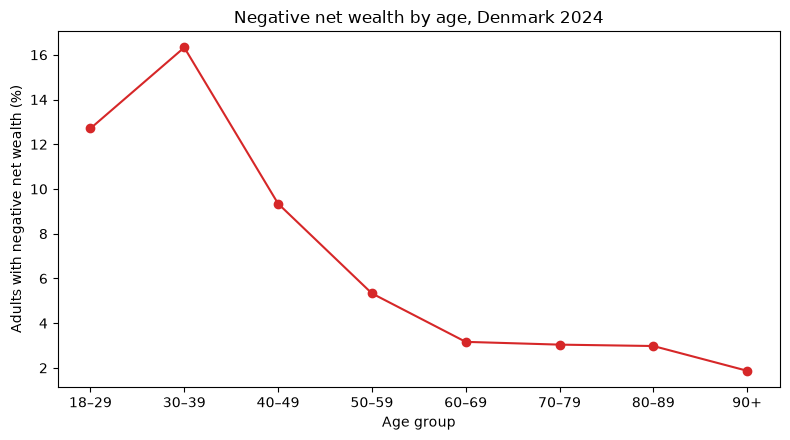

,age_group,10,50,90,negative_pct
0,18–29,-19750.0,66507.0,532429.0,12.7
1,30–39,-146586.0,353896.0,1780078.0,16.3
2,40–49,912.0,1004750.0,3688269.0,9.3
3,50–59,113324.0,1674287.0,5665305.0,5.3
4,60–69,239280.0,2147564.0,6883537.0,3.2
5,70–79,171695.0,1724056.0,6415595.0,3.0
6,80–89,99096.0,1146853.0,5305568.0,3.0
7,90+,69252.0,761637.0,4225415.0,1.9


All-adult share with negative net wealth: 8.3%


In [4]:
# The first three FORMUE15 brackets are below zero net wealth.
negative_brackets = ['0000M10', 'M100M05', 'M050000']
negative_by_age = (
    counts_age.loc[counts_age['FORMUE'].isin(negative_brackets)]
    .groupby('ALDER')['value'].sum()
    .reindex(age_codes)
)
count_by_age = counts_age.groupby('ALDER')['value'].sum().reindex(age_codes)
negative_share_by_age = 100 * negative_by_age / count_by_age

# Compare the sum of the eight age groups with the published all-adult count.
all_adult_count = counts_all['value'].sum()
age_count_sum = count_by_age.sum()
print(f'Age-group counts sum to {age_count_sum:,.0f}; published all-adult count is {all_adult_count:,.0f}.')
print('Counts match:', np.isclose(age_count_sum, all_adult_count))

negative_all_adult = counts_all.loc[counts_all['FORMUE'].isin(negative_brackets), 'value'].sum()
negative_all_adult_pct = 100 * negative_all_adult / all_adult_count

# Merge the negative-wealth share with the percentile profile, checking one row per age.
negative_profile = pd.DataFrame({
    'ALDER': age_codes,
    'negative_count': negative_by_age.to_numpy(),
    'population_count': count_by_age.to_numpy(),
    'negative_pct': negative_share_by_age.to_numpy(),
})
percentile_profile = wealth_percentiles[[10, 50, 90]].reset_index()
negative_profile = pd.merge(
    percentile_profile, negative_profile, on='ALDER', how='inner', validate='1:1'
)
negative_profile['age_group'] = age_labels

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(negative_profile['age_group'], negative_profile['negative_pct'], marker='o', color='tab:red')
ax.set_xlabel('Age group')
ax.set_ylabel('Adults with negative net wealth (%)')
ax.set_title('Negative net wealth by age, Denmark 2024')
fig.tight_layout()
plt.show()

display(negative_profile[['age_group', 10, 50, 90, 'negative_pct']].round(1))
print(f'All-adult share with negative net wealth: {negative_all_adult_pct:.1f}%')

**Interpretation.** The negative-wealth share is highest among ages 30–39 (16.3%) and falls to 1.9% among adults aged 90+. This does not exactly mirror the median profile: the median rises to ages 60–69 and then falls, while the negative-wealth share generally declines with age. The negative tail can therefore change substantially even when the median remains positive. The eight age-group counts sum exactly to the published all-adult count (4,851,818).

## 2.1   Give Everybody Their Age-Group Median
Tasks and hints: PDF Section 2.1.

In [5]:
from wealth_simulation import simulate_median_economy

# Counts define the age shares; align them with the percentile table's age order.
age_counts = count_by_age.to_numpy(dtype=float)
age_shares = age_counts / age_counts.sum()
age_medians = wealth_percentiles.loc[age_codes, 50].to_numpy(dtype=float)

assert np.isclose(age_shares.sum(), 1)

median_age, median_wealth = simulate_median_economy(
    age_shares=age_shares,
    age_medians=age_medians,
    n=10_000,
    seed=42,
)
simulated_age_shares = np.bincount(median_age, minlength=len(age_codes)) / len(median_age)
share_comparison = pd.DataFrame({
    'age_group': age_labels,
    'published_share_pct': 100 * age_shares,
    'simulated_share_pct': 100 * simulated_age_shares,
})
display(share_comparison.round(2))
print('Small share differences are expected because the simulated population is a random sample of 10,000 adults.')

,age_group,published_share_pct,simulated_share_pct
0,18–29,19.11,19.42
1,30–39,16.16,16.24
2,40–49,14.59,14.38
3,50–59,16.53,17.03
4,60–69,14.63,14.26
5,70–79,11.98,11.79
6,80–89,6.02,5.78
7,90+,0.98,1.10


Small share differences are expected because the simulated population is a random sample of 10,000 adults.


**Interpretation.** The simulated age shares are close to the published shares, but not identical because 10,000 random draws do not reproduce the population proportions exactly. The seed makes the same sample reproducible when the cell is rerun.

## 2.2   Allow Wealth to Vary Within Each Age Group
Tasks and hints: PDF Section 2.2.

In [6]:
from wealth_simulation import simulate_percentile_economy

# Rows are age groups and columns are P1, P2, ..., P99 (numeric order).
percentile_values = wealth_percentiles.loc[age_codes, range(1, 100)].to_numpy(dtype=float)
assert percentile_values.shape == (len(age_codes), 99)

within_age, within_age_wealth = simulate_percentile_economy(
    age_shares=age_shares,
    percentile_values=percentile_values,
    n=10_000,
    seed=42,
)
print(f'Simulated {len(within_age_wealth):,} adults; all wealth values are in DKK.')

Simulated 10,000 adults; all wealth values are in DKK.


## 2.3   Compare Both Economies with Denmark
Tasks and hints: PDF Section 2.3.

In [7]:
# Summarize simulated distributions and the published all-adult Denmark data.
def wealth_statistics(wealth):
    """Return the requested wealth percentiles, spread and negative-wealth share."""
    p10, p50, p90 = np.percentile(wealth, [10, 50, 90])
    return {
        'P10': p10,
        'P50': p50,
        'P90': p90,
        'P90-P10': p90 - p10,
        'Negative wealth (%)': 100 * np.mean(wealth < 0),
    }

all_adult_percentiles = percentiles_all.assign(
    percentile=percentiles_all['PERCENTIL'].str.replace('P', '', regex=False).astype(int)
).set_index('percentile')['value']
denmark = {
    'P10': all_adult_percentiles.loc[10],
    'P50': all_adult_percentiles.loc[50],
    'P90': all_adult_percentiles.loc[90],
    'P90-P10': all_adult_percentiles.loc[90] - all_adult_percentiles.loc[10],
    'Negative wealth (%)': negative_all_adult_pct,
}

comparison = pd.DataFrame({
    'Observed Denmark': denmark,
    'Age-group medians only': wealth_statistics(median_wealth),
    'Variation within age groups': wealth_statistics(within_age_wealth),
}).T
print('Wealth statistics (DKK except negative-wealth percentage):')
display(comparison.round(1))

median_gap_share = 100 * comparison.loc['Age-group medians only', 'P90-P10'] / denmark['P90-P10']
print(f'The age-group-median economy reproduces {median_gap_share:.1f}% of Denmark’s observed P90–P10 gap.')
print(f'Negative wealth in the median-only economy: {comparison.loc["Age-group medians only", "Negative wealth (%)"]:.1f}%.')
print('The full within-age simulation should be close, but not identical: it samples only 10,000 adults and represents each percentile by its threshold.')

Wealth statistics (DKK except negative-wealth percentage):


,P10,P50,P90,P90-P10,Negative wealth (%)
Observed Denmark,3386.0,800814.0,4475610.0,4472224.0,8.3
Age-group medians only,66507.0,1004750.0,2147564.0,2081057.0,0.0
Variation within age groups,6636.0,797414.0,4359441.0,4352805.0,7.9


The age-group-median economy reproduces 46.5% of Denmark’s observed P90–P10 gap.
Negative wealth in the median-only economy: 0.0%.
The full within-age simulation should be close, but not identical: it samples only 10,000 adults and represents each percentile by its threshold.


**Interpretation.** Giving everyone their age-group median reproduces about 46.5% of Denmark’s observed $P90-P10$ gap. It produces no negative wealth because every age-group median is positive, so every simulated adult receives positive wealth. Allowing wealth to vary within age groups brings the statistics close to Denmark: its simulated $P50$ is DKK 797,414 versus DKK 800,814 observed, and 7.9% versus 8.3% have negative wealth. The remaining difference is expected because this is a finite random sample of 10,000 and the simulation uses only P1–P99: it omits the very bottom and top 1% of the wealth distribution.

## 2.4   An Older Denmark
Tasks and hints: PDF Section 2.4.

In [8]:
# Shift five percentage points from ages 18–29 to ages 70–79.
older_age_shares = age_shares.copy()
older_age_shares[0] -= 0.05
older_age_shares[5] += 0.05
assert np.isclose(older_age_shares.sum(), 1.0)
assert np.all(older_age_shares >= 0)

older_age, older_wealth = simulate_percentile_economy(
    age_shares=older_age_shares,
    percentile_values=percentile_values,
    n=10_000,
    seed=42,  # same seed makes the counterfactual comparison less noisy
)

older_comparison = pd.DataFrame({
    'Observed Denmark': denmark,
    'Current age shares': wealth_statistics(within_age_wealth),
    'Older age shares': wealth_statistics(older_wealth),
}).T
print('Wealth statistics (DKK except negative-wealth percentage):')
display(older_comparison.round(1))
print('Change from current to older age shares:')
display((older_comparison.loc['Older age shares'] - older_comparison.loc['Current age shares']).round(1).to_frame('change'))
print('The age-specific wealth profiles are held fixed; only population shares change.')

Wealth statistics (DKK except negative-wealth percentage):


,P10,P50,P90,P90-P10,Negative wealth (%)
Observed Denmark,3386.0,800814.0,4475610.0,4472224.0,8.3
Current age shares,6636.0,797414.0,4359441.0,4352805.0,7.9
Older age shares,10570.0,930412.0,4631508.0,4620938.0,7.4


Change from current to older age shares:


,change
P10,3934.0
P50,132998.0
P90,272067.0
P90-P10,268133.0
Negative wealth (%),-0.5


The age-specific wealth profiles are held fixed; only population shares change.


**Interpretation.** Moving five percentage points from ages 18–29 to 70–79 raises the simulated median from DKK 797,414 to DKK 930,412 and widens the $P90-P10$ gap from DKK 4,352,805 to DKK 4,620,938. The negative-wealth share falls from 7.9% to 7.4%. This follows the 2024 age profiles: the 70–79 group has higher percentiles and a smaller negative-wealth share than the 18–29 group. The age profiles also explain the wider spread: the upper gap ($P90-P50$) is about DKK 4.7 million for ages 70–79, compared with about DKK 0.5 million for ages 18–29. Moving population share toward the group with the much larger upper gap raises the overall upper tail and widens the $P90-P10$ gap. Using the same seed holds the random draws as comparable as possible, so differences mainly reflect the changed age shares. In reality, age-specific wealth profiles could also change as people save, retire, inherit, or face different housing and asset prices.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).
